# 04 · 相似度模型（Similarity Model）

**目标**：输入一名球员，找出**踢法最像**的球员，并能按 **预算、年龄、联赛、惯用脚** 筛选。

| 部分 | 内容 |
|---|---|
| 1 | 载入数据和相似度模块 `src/similarity.py` |
| 2 | 模型是怎么运作的 |
| 3 | 案例测试：5 名知名球员 |
| 4 | 加上 App 的筛选条件 |
| 5 | 雷达图：目标 vs 最像的人 |
| 6 | **评估**：怎么证明模型有效？ |

💡 核心代码放在 `src/similarity.py`，这样**阶段 7 的 Streamlit App 可以直接重复使用**，不用复制贴上。
这在软件工程里叫 **DRY 原则（Don't Repeat Yourself）**。

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))          # 让 Python 找得到 src/ 文件夹

from src.similarity import SimilarityModel, FEATURES, FEATURES_V1, LABELS

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "text.color": "#0b0b0b", "font.size": 10})

df = pd.read_csv(ROOT / "data" / "processed" / "players_2025_26.csv")
model = SimilarityModel(df)
print("球员人数：", len(df))
for pos, cols in FEATURES.items():
    print(f"{pos}: {[LABELS[c] for c in cols]}")

球员人数： 1410
FW: ['npxG', 'Shots', 'xA', 'Offsides', 'Fouled', 'Crosses', 'Header %', 'Shot distance', 'Self-created %']
MF: ['xA', 'xG Buildup', 'Interceptions', 'Tackles won', 'Fouls', 'npxG', 'Crosses']
DF: ['Interceptions', 'Tackles won', 'Crosses', 'xG Buildup', 'Fouls', 'Height', 'xA']


## 2️⃣ 模型是怎么运作的

| 步骤 | 做什么 | 第 0 课的哪一课 |
|---|---|---|
| ① 分位置 | 前锋只和前锋比，后卫只和后卫比 | 不同位置用不同指标 |
| ①b 分角色 | 默认**中锋只和中锋比、边锋只和边锋比**（`same_role=True`，可以关掉） | 你在阶段 4 提出的改进 |
| ② 标准化 | 每个指标换算成“比**同位置**平均高或低几个标准差” | Standardization（体重 克 vs 身高 米） |
| ③ Cosine | 比较两人的指标**比例（风格）**像不像 | 酱料比例：小店 vs 大店 |

⚠️ **为什么只在同位置里标准化？** 如果和所有人一起算，后卫的拦截永远“很高”、前锋的 xG 永远“很高”，
我们就只是在分辨位置，而不是分辨**同一位置里不同的踢法**。

## 3️⃣ 案例测试

用你熟悉的球员测试，看结果**符不符合你的足球常识**。这叫 **face validity（表面效度）**。

In [2]:
for name in ["Pedri", "Virgil van Dijk", "Bukayo Saka", "Erling Haaland"]:
    print(f"\n🎯 最像 {name} 的球员：")
    display(model.find_similar(name, n=5))


🎯 最像 Pedri 的球员：


,player,squad,league,role,sub_position,age,foot,minutes,value_end,similarity
851,Frenkie de Jong,Barcelona,ESP-La Liga,CM,Central Midfield,29.1,right,1636,35.0,0.972
1081,Tom Bischof,Bayern Munich,GER-Bundesliga,CM,Central Midfield,21.0,left,1302,40.0,0.958
932,Rodri,Manchester City,ENG-Premier League,CM,Defensive Midfield,30.0,right,1511,50.0,0.909
445,Koke,Atlético Madrid,ESP-La Liga,CM,Central Midfield,34.5,right,2219,5.0,0.893
401,Joshua Kimmich,Bayern Munich,GER-Bundesliga,CM,Defensive Midfield,31.4,right,2280,35.0,0.855



🎯 最像 Virgil van Dijk 的球员：


,player,squad,league,role,sub_position,age,foot,minutes,value_end,similarity
4,Nikola Milenković,Nottingham,ENG-Premier League,CB,Centre-Back,28.7,right,3375,28.0,0.972
1058,Tyrone Mings,Aston Villa,ENG-Premier League,CB,Centre-Back,33.3,left,1324,3.0,0.944
822,Pau Torres,Aston Villa,ENG-Premier League,CB,Centre-Back,29.5,left,1676,20.0,0.926
86,Joe Rodon,Leeds United,ENG-Premier League,CB,Centre-Back,28.7,right,2951,18.0,0.923
119,Matthias Ginter,Freiburg,GER-Bundesliga,CB,Centre-Back,32.4,right,2833,5.0,0.920



🎯 最像 Bukayo Saka 的球员：


,player,squad,league,role,sub_position,age,foot,minutes,value_end,similarity
352,Nicolas Pépé,Villarreal,ESP-La Liga,W,Right Winger,31.1,left,2393,6.0,0.892
389,Michael Olise,Bayern Munich,GER-Bundesliga,W,Right Winger,24.5,left,2316,150.0,0.891
128,Kenan Yıldız,Juventus,ITA-Serie A,W,Left Winger,21.2,both,2825,75.0,0.846
410,Lamine Yamal,Barcelona,ESP-La Liga,W,Right Winger,19.0,left,2262,200.0,0.825
325,Florian Thauvin,Lens,FRA-Ligue 1,W,Right Winger,33.4,left,2443,5.0,0.813



🎯 最像 Erling Haaland 的球员：


,player,squad,league,role,sub_position,age,foot,minutes,value_end,similarity
1123,Christian Kofane,Leverkusen,GER-Bundesliga,ST,Centre-Forward,19.9,right,1239,40.0,0.967
585,Patrik Schick,Leverkusen,GER-Bundesliga,ST,Centre-Forward,30.4,left,1988,18.0,0.961
717,Hugo Ekitike,Liverpool,ENG-Premier League,ST,Centre-Forward,24.0,right,1803,80.0,0.906
376,Serhou Guirassy,Dortmund,GER-Bundesliga,ST,Centre-Forward,30.3,right,2337,32.0,0.905
603,Ferran Torres,Barcelona,ESP-La Liga,ST,Centre-Forward,26.3,right,1965,50.0,0.896


🤔 **看看结果，用你的足球常识判断合不合理**。例如：

- Pedri 的推荐里是不是都是**控球型中场**？
- Saka 的推荐里是不是很多**左脚的右边锋**？（模型根本不知道惯用脚，如果出现了，就是数据自己找出来的！）
- Haaland 的推荐里有 Schick，但身价差了 10 倍，为什么？👇（第 5 部分）

⚠️ 记住第 0 课的教训：**Cosine 只看风格比例、不看份量**。所以推荐名单出来后，还要检查**实际产出**，阶段 6 会加上“产出门槛”。

## 3️⃣b 改进前 vs 改进后：Barcola 问题

你在 v1 发现 **Barcola（边锋）被推荐成 Haaland 的平替**。v2 做了两个改进：

| 改进 | 内容 |
|---|---|
| 新指标 | 头球比例、平均射门距离、无人助攻射门比例（阶段 2 的 7️⃣b）、传中 |
| 分角色 | 默认只和同角色比较 |

下面**故意关掉分角色**（`same_role=False`），只看**新指标本身**有没有帮助：

In [3]:
model_v1 = SimilarityModel(df, features=FEATURES_V1)

for label, m in [("v1（旧指标）", model_v1), ("v2（新指标）", model)]:
    _, out = m.similarity_to("Erling Haaland")
    out = out.sort_values("similarity", ascending=False).reset_index(drop=True)
    rank = out.index[out["player"] == "Bradley Barcola"][0] + 1
    print(f"{label}：Barcola 在 Haaland 的推荐中排第 {rank} 名")
    display(out[["player", "role", "sub_position", "similarity"]].head(6))

v1（旧指标）：Barcola 在 Haaland 的推荐中排第 5 名


,player,role,sub_position,similarity
0,Patrik Schick,ST,Centre-Forward,0.989
1,Christian Kofane,ST,Centre-Forward,0.986
2,Igor Matanović,ST,Centre-Forward,0.948
3,Rômulo,ST,Centre-Forward,0.918
4,Bradley Barcola,W,Left Winger,0.914
5,Ferran Torres,ST,Centre-Forward,0.909


v2（新指标）：Barcola 在 Haaland 的推荐中排第 16 名


,player,role,sub_position,similarity
0,Christian Kofane,ST,Centre-Forward,0.967
1,Patrik Schick,ST,Centre-Forward,0.961
2,Hugo Ekitike,ST,Centre-Forward,0.906
3,Serhou Guirassy,ST,Centre-Forward,0.905
4,Ferran Torres,ST,Centre-Forward,0.896
5,Rômulo,ST,Centre-Forward,0.884


💡 v2 就算**允许跨位置**，前几名也几乎都是中锋了：**新指标本身就能分辨中锋和边锋**。
再加上默认的“只比同角色”，Barcola 就不会再出现了。

新指标的雷达图长这样（Haaland vs 一名边锋）：

## 4️⃣ 加上 App 的 4 个筛选条件

情境：一支西甲中游球队想找 **“Pedri 那种踢法”**，但**预算只有 30M**、要 **27 岁以下**、**右脚**。

💡 惯用脚筛选的规则：选 `right` 时，**双脚球员（both）也算符合**，因为他们也能踢右脚位置（你之前问过的问题）。

In [4]:
display(model.find_similar("Pedri", n=8, max_value=30, age_range=(18, 27), foot="right"))

# 只看意甲、法甲
display(model.find_similar("Virgil van Dijk", n=5, max_value=20, leagues=["ITA-Serie A", "FRA-Ligue 1"]))

,player,squad,league,role,sub_position,age,foot,minutes,value_end,similarity
1069,Miguel Román,Celta Vigo,ESP-La Liga,CM,Central Midfield,23.5,right,1311,15.0,0.769
419,Timothy Weah,Marseille,FRA-Ligue 1,CM,Right Midfield,26.4,right,2253,20.0,0.744
143,Alexis Saelemaekers,Milan,ITA-Serie A,CM,Right Midfield,27.0,right,2788,20.0,0.710
259,Nicolò Fagioli,Fiorentina,ITA-Serie A,CM,Central Midfield,25.4,right,2554,16.0,0.628
1338,Assan Ouédraogo,RB Leipzig,GER-Bundesliga,CM,Central Midfield,20.1,right,948,28.0,0.625
952,Maxence Caqueret,Como,ITA-Serie A,CM,Central Midfield,26.4,right,1485,13.0,0.619
762,Azzedine Ounahi,Girona,ESP-La Liga,CM,Central Midfield,26.2,right,1760,10.0,0.611
1199,Khalis Merah,Lyon,FRA-Ligue 1,CM,Central Midfield,19.3,right,1130,15.0,0.607


,player,squad,league,role,sub_position,age,foot,minutes,value_end,similarity
1169,Diego Coppola,Paris FC,FRA-Ligue 1,CB,Centre-Back,22.5,right,1364,18.0,0.912
732,Lucas Høgsberg,Strasbourg,FRA-Ligue 1,CB,Centre-Back,20.0,right,1792,18.0,0.884
229,Montassar Talbi,Lorient,FRA-Ligue 1,CB,Centre-Back,28.1,right,2610,8.0,0.866
994,Abdelhamid Ait Boudlal,Rennes,FRA-Ligue 1,CB,Centre-Back,20.2,right,1403,12.0,0.840
302,Thomas Kristensen,Udinese,ITA-Serie A,CB,Centre-Back,24.4,right,2472,12.0,0.831


## 5️⃣ 雷达图：目标 vs 最像的人

雷达图是**球探报告最常用的图**。每个轴是一个指标，数值是**在同位置里的百分位**（0-100）：
80 = 比 80% 的同位置球员高。两个形状越重叠，代表踢法越像。

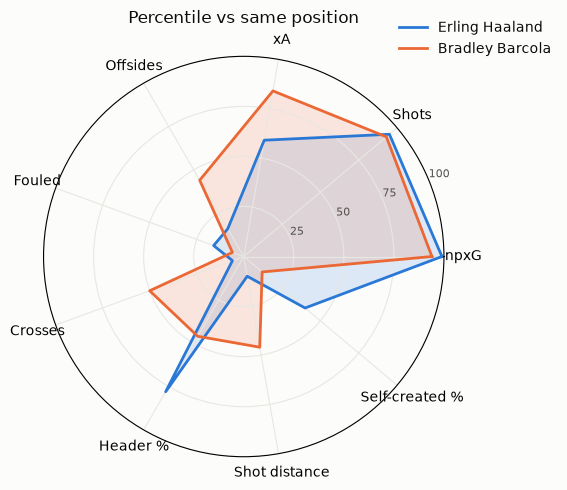

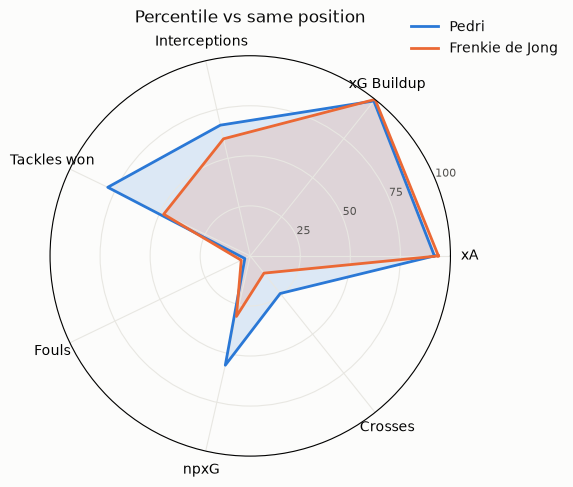

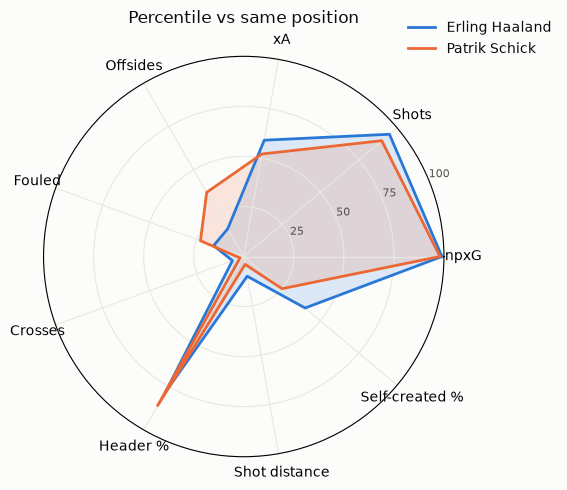

In [5]:
def radar(name_a, name_b):
    pa, pb = model.percentiles(name_a), model.percentiles(name_b)
    labels = list(pa.index)
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    angles += angles[:1]
    fig, ax = plt.subplots(figsize=(5.2, 5.2), subplot_kw={"polar": True})
    for p, name, c in [(pa, name_a, "#2a78d6"), (pb, name_b, "#eb6834")]:
        vals = p.tolist() + p.tolist()[:1]
        ax.plot(angles, vals, color=c, lw=2, label=name)
        ax.fill(angles, vals, color=c, alpha=0.15)
    ax.set_xticks(angles[:-1], labels)
    ax.set_ylim(0, 100); ax.set_yticks([25, 50, 75, 100], ["25", "50", "75", "100"], color="#52514e", fontsize=8)
    ax.grid(color="#e8e7e2")
    ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.12), frameon=False)
    ax.set_title("Percentile vs same position", pad=24)
    plt.show()

radar("Erling Haaland", "Bradley Barcola")   # 中锋 vs 边锋：头球、射门距离、传中差很多
radar("Pedri", "Frenkie de Jong")
radar("Erling Haaland", "Patrik Schick")

🤔 第一张图：Haaland 和 Barcola 的**头球比例、射门距离、传中**差很多，这就是 v2 能分辨他们的原因。

第三张图：Haaland 和 Schick 的形状**很接近**。下面直接比较原始数字：

In [ ]:
display(df[df.player.isin(["Erling Haaland", "Patrik Schick"])][
    ["player", "age", "league", "minutes", "npxg_p90", "shots_p90", "goals_p90", "value_end"]])

有趣的发现：Schick **每 90 分钟**的产出（npxG 0.71 vs 0.79）其实**和 Haaland 很接近**！身价差 10 倍，主要来自：

| 差异 | Haaland | Schick |
|---|---|---|
| 年龄 | 25 岁 | 30 岁（转售价值低） |
| 上场时间 | 2,953 分钟 | 1,988 分钟（可用性 / 伤病风险） |
| 联赛 | 英超（溢价） | 德甲 |

这正是“平替”的典型例子：**踢法和效率接近，但因为年龄、出勤、联赛而便宜很多**。
不过 per-90 数据在出场较少时**波动更大**（Striker F 的教训），所以 App 里要同时显示**出场时间**，让使用者自己判断可靠度。

## 6️⃣ 评估：怎么证明模型有效？

相似度是**非监督学习**，没有“标准答案”。所以用一个**间接**的方法检验：

> 模型**没看过** Transfermarkt 的细分位置（左边锋、中卫、后腰…）。
> 如果模型推荐的前 10 名里，**和目标同一细分位置**的比例远高于“随便乱选”，
> 就代表模型**自己从数据里学到了踢法的差异**。

🍜 比喻：蒙眼试吃，如果你能把“猪肠粉”和“猪肠粉”配在一起的次数远多于乱猜，就证明你的舌头真的能分辨口味。

- **Model**：前 10 名中，同细分位置的比例
- **Random baseline**：在同一大位置里随便抽 10 人，同细分位置的比例

In [6]:
def same_subpos_rate(m, k=10):
    rows = []
    for i in df.index:
        name = df.at[i, "player"]
        _, out = m.similarity_to(name)          # 不分角色：测试“指标本身”的分辨能力
        top = out.nlargest(k, "similarity")
        model_rate = (top["sub_position"] == df.at[i, "sub_position"]).mean()
        # 随机基准：同大位置里，同细分位置的人占多少比例
        rest = out["sub_position"]
        random_rate = (rest == df.at[i, "sub_position"]).mean()
        rows.append({"pos_group": df.at[i, "pos_group"], "model": model_rate, "random": random_rate})
    return pd.DataFrame(rows)

results = {}
for label, m in [("v1", model_v1), ("v2", model)]:
    ev = same_subpos_rate(m)
    t = ev.groupby("pos_group")[["model", "random"]].mean()
    t.loc["ALL"] = ev[["model", "random"]].mean()
    results[label] = t

compare = pd.DataFrame({
    "Random %": results["v1"]["random"] * 100,
    "v1 Model %": results["v1"]["model"] * 100,
    "v1 lift": results["v1"]["model"] / results["v1"]["random"],
    "v2 Model %": results["v2"]["model"] * 100,
    "v2 lift": results["v2"]["model"] / results["v2"]["random"],
}).round(2)
display(compare)

,Random %,v1 Model %,v1 lift,v2 Model %,v2 lift
pos_group,,,,,
DF,40.31,69.36,1.72,69.93,1.73
FW,34.03,51.89,1.52,58.22,1.71
MF,34.34,42.73,1.24,47.05,1.37
ALL,36.65,55.91,1.53,59.28,1.62


**怎么读这张表**：`lift` = 模型比乱选好几倍。大于 1 就代表模型有学到东西，越大越好。
比较 **v1 lift** 和 **v2 lift**，就知道你提出的改进**有没有用、用多少**，这是报告里很有说服力的一段。

💡 这里故意**不分角色**来评估。如果分角色，同细分位置的比例本来就会很高，那是“规定出来的”，不是模型学到的。

⚠️ **这个评估的限制**（要写进报告）：同细分位置**不等于**踢法一样（例如有的中卫擅长出球，有的只会防守），
所以这只是**间接证据**。阶段 8 可以再加“专家检查”或“跨赛季稳定性”等方法。

⚠️ **速度**无法衡量：需要付费的追踪数据（tracking data）。目前只能用越位次数、无人助攻射门比例当作**部分近似**，要写进 *Limitations*。

## 🤔 思考题（选择题，选一个就好）

**Q1**：如果**不分位置**，直接把所有球员放在一起计算相似度，最可能发生什么？
- A. 结果完全一样
- B. 推荐名单会被“位置”主导，后卫只会推荐后卫，看不出同位置内的风格差异
- C. 程序会报错

**Q2**：Haaland 的平替推荐了 Schick（身价 18M）。Schick 能直接取代 Haaland 吗？
- A. 能，相似度 0.99 很高，什么都不用再检查
- B. 风格和每 90 分钟效率接近，但还要考虑年龄、上场时间（伤病风险）这些相似度没有算进去的因素

**Q3**：评估表里的 `lift` 如果是 **1.0**，代表什么？
- A. 模型完美
- B. 模型和随便乱选一样，没有学到东西